# 01 · Model exploration: learning an online dispatcher from a batch optimiser

This notebook is the **research log** behind `app/ml/train.py`. It answers, with evidence:

1. *Is there anything to learn?* Does the optimal (Hungarian) solution differ from "pick the cheapest technician"?
2. *How should the problem be framed?* Classification vs learning-to-rank, and which metric matters.
3. *How should data be split?* Why rows from one scenario must never be on both sides of a split.
4. *Which model, which hyper-parameters, which features?* Model comparison, sweep, learning curve, ablation.
5. *Where does it fail and why?* Error analysis, calibration, SHAP explanations.
6. *Does a better ML metric translate into better dispatch?* Outcome metrics of the online ML dispatcher vs batch Hungarian.

**Production code is imported, not copied** (`build_dataset`, `candidate_features`, `fit`, `allocate_*`), so
whatever is concluded here is exactly what the API serves.

| Notebook section | Production counterpart |
|---|---|
| Dataset build (teacher forcing) | `app/ml/dataset.py` |
| Features | `app/ml/features.py` |
| Model factory / fit | `app/ml/train.py::make_model`, `fit` |
| Metrics | `app/ml/evaluate.py` |
| Inference + explanations | `app/algorithms/ml_dispatcher.py`, `app/ml/scorer.py` |

## 0 · Setup

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold

# Make the backend package importable from notebooks/
BACKEND = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(BACKEND))

from app.algorithms.hungarian import allocate_hungarian
from app.algorithms.ml_dispatcher import allocate_online
from app.data.generator import PRESETS, generate_preset, generate_scenario
from app.ml.dataset import build_dataset, random_scenarios
from app.ml.evaluate import agreement, business_eval
from app.ml.features import FEATURE_NAMES
from app.ml.scorer import Scorer
from app.ml.train import fit, make_model
from app.models import Weights

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 10_000          # same seed as train.py -> identical scenarios and split
N_SCENARIOS = 200
WEIGHTS = Weights()    # soft-constraint weights the teacher optimises
print("backend:", BACKEND)

backend: C:\Users\IPCXRB\Raaghu_KB\Avtn_casestudy\backend


## 1 · Problem framing

**Setting.** Requests arrive during the day (`requested_at`). An *online* dispatcher must assign each request
immediately, seeing only the current fleet state. A *batch* optimiser (Hungarian in rounds) sees the whole day and
trades off jobs against each other - but it is only available in hindsight or for next-day planning.

**Idea - imitation learning (behavioural cloning).** Use the batch optimiser as a *teacher*: solve many synthetic
days with Hungarian, then replay each day in request order and, at every request, record

* the feasible candidate technicians (hard constraints already applied),
* a feature vector per candidate (computed from information available *at that moment*),
* the label: 1 for the technician Hungarian chose, 0 otherwise.

The model learns a scoring function $s(x)$ such that $\arg\max_{c \in C_d} s(x_c)$ recovers the teacher's choice
for decision $d$.

**Teacher forcing.** During replay we commit the *teacher's* choice (not the model's), so the fleet state follows
the teacher's plan. This makes labels well-defined but creates a known gap: at inference time the model visits
states produced by its own earlier decisions, which it never saw in training (*compounding error*, Ross et al. 2011).
We measure this in section 9.

**Why a ranking problem, not plain classification?** Each decision has exactly one positive among $|C_d|$
candidates, and only the *relative* order within a decision matters. A score of 0.3 is great if all other
candidates score 0.1, and useless if one scores 0.4. That suggests a learning-to-rank objective
(LambdaRank optimises NDCG within each query group = decision).

## 2 · Build the dataset

`build_dataset` runs Hungarian on every scenario (teacher), then replays the scenario online with teacher forcing.
A teacher assignment can be *unreplayable*: Hungarian builds routes round by round, while the replay processes
requests in arrival order, so occasionally the teacher's technician is already committed later in the day when the
request arrives. Those decisions are skipped and reported as `coverage`.

In [2]:
t0 = time.perf_counter()
scenarios = random_scenarios(N_SCENARIOS, SEED)
ds = build_dataset(scenarios, WEIGHTS)
print(f"built in {time.perf_counter() - t0:.1f}s")

df = pd.DataFrame(ds.X, columns=FEATURE_NAMES)
df["label"] = ds.y
df["scenario_id"] = ds.scenario_ids
df["decision_id"] = ds.decision_ids

meta = pd.DataFrame({
    "scenario_id": range(len(scenarios)),
    "n_techs": [len(s.technicians) for s in scenarios],
    "n_jobs": [len(s.jobs) for s in scenarios],
})
meta["demand_ratio"] = meta.n_jobs / meta.n_techs
df = df.merge(meta, on="scenario_id", how="left")

dec = df.groupby("decision_id").agg(n_cand=("label", "size"), scenario_id=("scenario_id", "first"))
summary = pd.Series({
    "scenarios": len(scenarios),
    "rows (candidate pairs)": len(df),
    "decisions": len(dec),
    "positives": int(df.label.sum()),
    "positive rate (rows)": df.label.mean(),
    "teacher coverage in replay": ds.coverage,
    "decisions with 1 candidate (trivial)": (dec.n_cand == 1).mean(),
    "mean candidates / decision": dec.n_cand.mean(),
})
display(summary.to_frame("value"))

built in 26.6s


,value
scenarios,200.000
rows (candidate pairs),76480.000
decisions,13830.000
positives,13830.000
positive rate (rows),0.181
teacher coverage in replay,0.947
decisions with 1 candidate (trivial),0.111
mean candidates / decision,5.530


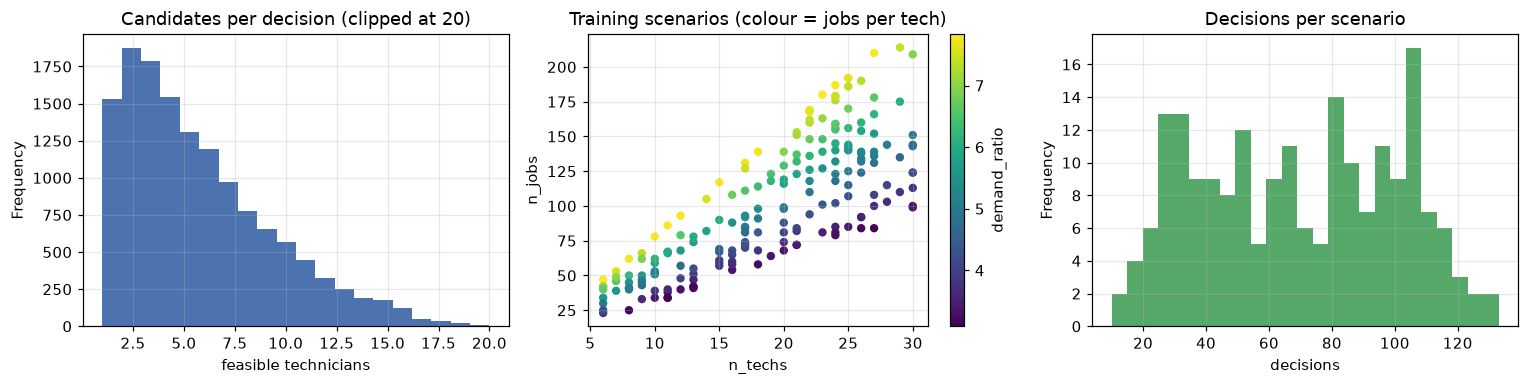

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
dec.n_cand.clip(upper=20).plot.hist(bins=20, ax=axes[0], color="#4c72b0")
axes[0].set(title="Candidates per decision (clipped at 20)", xlabel="feasible technicians")
meta.plot.scatter("n_techs", "n_jobs", c="demand_ratio", cmap="viridis", ax=axes[1])
axes[1].set(title="Training scenarios (colour = jobs per tech)")
df.groupby("scenario_id").decision_id.nunique().plot.hist(bins=25, ax=axes[2], color="#55a868")
axes[2].set(title="Decisions per scenario", xlabel="decisions")
plt.tight_layout()
plt.show()

**Reading the data.**
* Every decision has exactly one positive, so the *row-level* positive rate is just $1/\overline{|C_d|}$ - it is not a
  class-imbalance problem to "fix" with re-weighting; it is a ranking problem.
* Decisions with a single feasible candidate carry no learning signal for *choice* (the answer is forced).
  They stay in training (harmless) but are **excluded from top-k metrics**, otherwise accuracy is inflated.

## 3 · Is there anything to learn? Teacher vs "cheapest"

If Hungarian always picked the cheapest feasible technician, a model would be pointless - a `min()` would do.
`cost_rank` is the candidate's rank by soft-constraint cost within its decision (0 = cheapest).

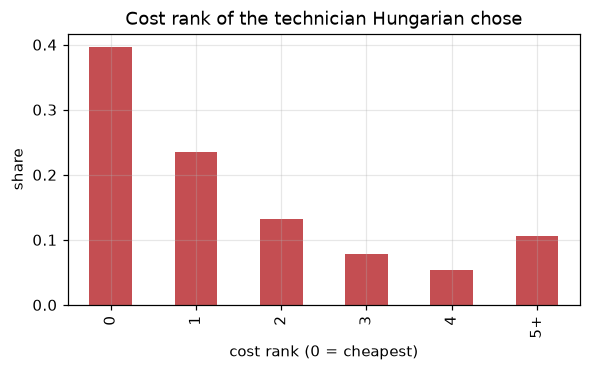

Teacher picks the cheapest candidate in 39.7% of non-trivial decisions


In [4]:
nontrivial = df[df.n_feasible >= 2]
chosen = nontrivial[nontrivial.label == 1]
rank_dist = chosen.cost_rank.clip(upper=5).value_counts(normalize=True).sort_index()
rank_dist.index = [str(int(i)) if i < 5 else "5+" for i in rank_dist.index]

fig, ax = plt.subplots(figsize=(6, 3.2))
rank_dist.plot.bar(ax=ax, color="#c44e52")
ax.set(title="Cost rank of the technician Hungarian chose", xlabel="cost rank (0 = cheapest)", ylabel="share")
plt.show()
print(f"Teacher picks the cheapest candidate in {rank_dist.iloc[0]:.1%} of non-trivial decisions")

**Insight.** The teacher picks the locally cheapest technician in well under half of the non-trivial decisions.
The rest of the time it sacrifices local cost because that technician is worth more elsewhere (another job only they
can do, or a better-fitting job later). That *opportunity cost* is exactly what a myopic greedy rule cannot see and
what the model must infer from features such as skill rarity, remaining capacity and slack.

Let's look at how chosen vs not-chosen candidates differ. Raw comparisons are confounded across decisions
(a far job makes everyone's travel large), so we also look at values **relative to the decision's mean**.

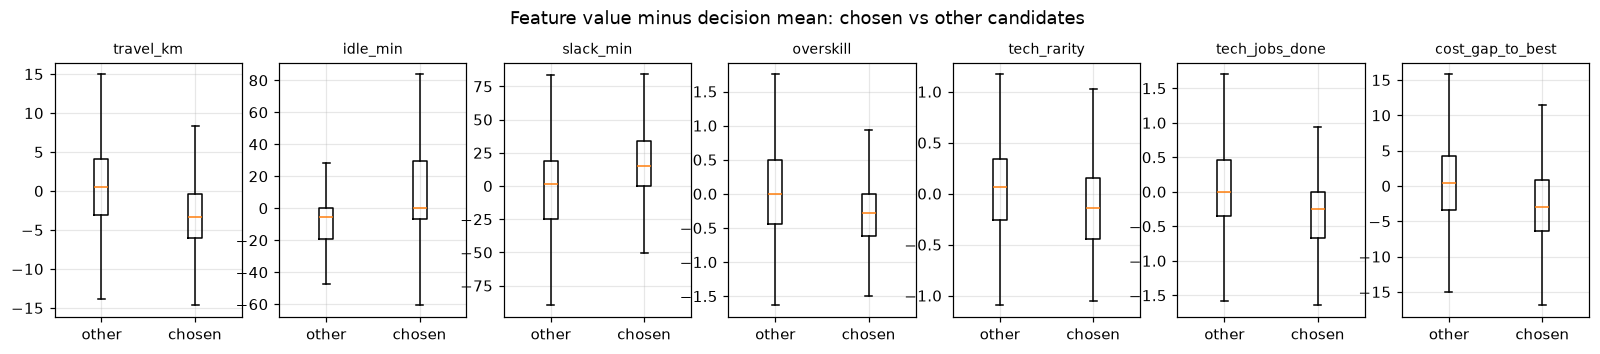

In [5]:
key = ["travel_km", "idle_min", "slack_min", "overskill", "tech_rarity", "tech_jobs_done", "cost_gap_to_best"]
rel = nontrivial[key + ["label", "decision_id"]].copy()
rel[key] = rel[key] - rel.groupby("decision_id")[key].transform("mean")

fig, axes = plt.subplots(1, len(key), figsize=(18, 3))
for ax, f in zip(axes, key):
    data = [rel.loc[rel.label == 0, f], rel.loc[rel.label == 1, f]]
    ax.boxplot(data, showfliers=False)
    ax.set_xticks([1, 2], ["other", "chosen"])
    ax.set_title(f, fontsize=9)
fig.suptitle("Feature value minus decision mean: chosen vs other candidates", y=1.04)
plt.show()

Patterns (medians of value minus decision mean, chosen vs others):
* chosen technicians are **closer** (~3.3 km below the decision mean) and **cheaper relative to their competitors**;
* they have **more slack** (arrive well before the window closes) and, surprisingly, **more idle time** - the teacher
  happily lets a technician wait for a well-matched job (explained in section 4);
* they are **less over-qualified**, have **lower skill rarity** (rare-skill technicians are kept free) and have
  **done fewer jobs so far** (load balancing).

Feature redundancy check - tree models cope with correlated features, but it matters for interpreting importances
(credit is split between correlated features) and for the linear baseline.

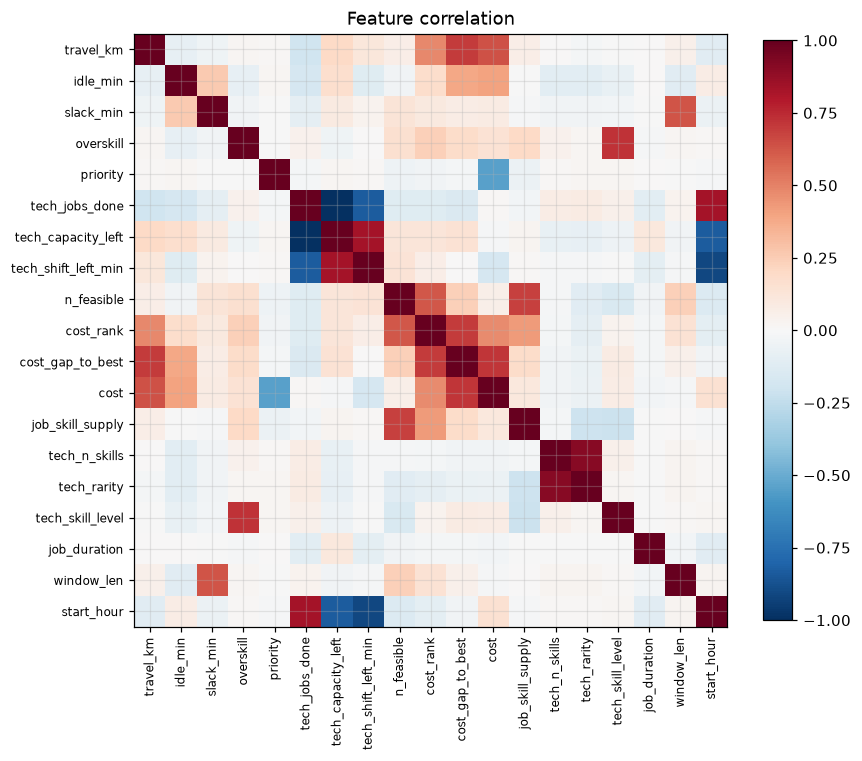

,,pearson r
tech_jobs_done,tech_capacity_left,-1.000
tech_shift_left_min,start_hour,-0.912
tech_n_skills,tech_rarity,0.907
tech_capacity_left,tech_shift_left_min,0.832
tech_jobs_done,tech_shift_left_min,-0.832
tech_capacity_left,start_hour,-0.831


In [6]:
corr = df[FEATURE_NAMES].corr()
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURE_NAMES)), FEATURE_NAMES, rotation=90, fontsize=8)
ax.set_yticks(range(len(FEATURE_NAMES)), FEATURE_NAMES, fontsize=8)
fig.colorbar(im, fraction=0.04)
ax.set_title("Feature correlation")
plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().sort_values(key=abs, ascending=False)
display(pairs.head(6).to_frame("pearson r"))

## 4 · Metrics and baselines

**Decision-level metrics (what the dispatcher actually does):**
* **Top-1** - share of non-trivial decisions where the highest-scored candidate is the teacher's pick. *Primary metric.*
* **Top-2** - teacher's pick is in the top two (useful if a human dispatcher confirms suggestions).
* **MRR** - mean reciprocal rank of the teacher's pick.

**AUC** is reported for completeness but is the *wrong* primary metric here: it compares candidates **across**
decisions (a near candidate in one decision vs a far one in another), while the dispatcher only ever compares
candidates **within** a decision. A model can improve within-decision ordering while AUC goes down - we will see
exactly this.

**Baselines** frame what "good" means: random choice, nearest technician, least idle, and cheapest (what a
greedy cost rule would pick).

In [7]:
def decision_metrics(frame: pd.DataFrame, scores: np.ndarray) -> dict:
    """Top-1 / top-2 / MRR over non-trivial decisions (higher score = better), plus pooled AUC."""
    d = frame[["decision_id", "label", "n_feasible"]].copy()
    d["score"] = scores
    d = d[d.n_feasible >= 2]
    d["rank"] = d.groupby("decision_id")["score"].rank(ascending=False, method="first")
    pos = d[d.label == 1]
    return {
        "top1": float((pos["rank"] == 1).mean()),
        "top2": float((pos["rank"] <= 2).mean()),
        "mrr": float((1 / pos["rank"]).mean()),
        "auc": float(roc_auc_score(d.label, d.score)),
    }


n = nontrivial.groupby("decision_id").size()
random_expected = {
    "top1": float((1 / n).mean()),
    "top2": float(np.minimum(2 / n, 1).mean()),
    "mrr": float(n.map(lambda k: sum(1 / r for r in range(1, k + 1)) / k).mean()),
    "auc": 0.5,
}
baselines = pd.DataFrame({
    "random (expected)": random_expected,
    "nearest (min travel_km)": decision_metrics(df, -df.travel_km.values),
    "least idle (min idle_min)": decision_metrics(df, -df.idle_min.values),
    "cheapest (min cost)": decision_metrics(df, -df.cost.values),
}).T
display(baselines)

,top1,top2,mrr,auc
random (expected),0.233,0.467,0.470,0.500
nearest (min travel_km),0.429,0.676,0.633,0.692
least idle (min idle_min),0.158,0.366,0.395,0.373
cheapest (min cost),0.397,0.632,0.602,0.621


**Two surprises worth explaining:**

1. **"Nearest" (0.43) beats "cheapest" (0.40)** even though the teacher minimises cost. The teacher minimises the
   *sum* of costs over a whole round, not each pair's cost. Distance is the term that is hardest to trade away
   globally, so it survives the global optimisation better than the other cost terms.
2. **"Least idle" (0.16) is worse than random (0.23)** - the teacher *prefers* candidates who will wait. This is an
   artefact of round-based Hungarian: each round gives every technician its best job *for that round*, which is often
   later in the day, so idle time is accepted to secure a good match. It is also why Hungarian shows the highest idle
   time in the outcome metrics (section 11).

Lesson: the teacher's behaviour is **not** a simple function of the cost formula, which is precisely why a learned
ranker can beat the cost rule at predicting it. The bar to clear is the best baseline (~0.43 top-1).

## 5 · Train/test protocol - and why splitting by scenario matters

Rows are **not i.i.d.**: candidates within a decision share the job; decisions within a scenario share technicians,
geography and the evolving fleet state. If rows from one scenario land in both train and test, the model can partly
memorise scenario-specific patterns and the test score overestimates performance on a *new day*.

Protocol (identical to `train.py`):
* 20 % of **scenarios** held out as the final test set, never touched during model selection;
* model selection with `GroupKFold(groups=scenario_id)` on the remaining 80 %.

Experiment: compare honest scenario-level CV with a leaky variant that only keeps decisions intact (scenarios leak).

In [8]:
rng = np.random.default_rng(SEED)
order = rng.permutation(N_SCENARIOS)
test_sids = set(order[: N_SCENARIOS // 5].tolist())
is_test = df.scenario_id.isin(test_sids).values
train_df, test_df = df[~is_test].reset_index(drop=True), df[is_test].reset_index(drop=True)
assert not set(train_df.scenario_id) & set(test_df.scenario_id)
print(f"train: {train_df.scenario_id.nunique()} scenarios / {len(train_df)} rows | "
      f"test: {test_df.scenario_id.nunique()} scenarios / {len(test_df)} rows")


def xyd(frame: pd.DataFrame, features: list[str] = FEATURE_NAMES):
    return frame[features].values, frame.label.values, frame.decision_id.values


def fit_custom(kind: str, X, y, d, **params) -> Scorer:
    """train.fit, plus optional hyper-parameter overrides for the sweep."""
    if not params:
        return fit(kind, X, y, d)
    model = make_model(kind).set_params(**params)
    if kind == "lgbm_ranker":
        _, sizes = np.unique(d, return_counts=True)  # decision ids are contiguous -> group sizes in row order
        model.fit(X, y, group=sizes)
    else:
        model.fit(X, y)
    return Scorer(kind, model, FEATURE_NAMES)


def cv_score(kind: str, frame: pd.DataFrame, groups: np.ndarray, features=FEATURE_NAMES, n_splits=3, **params) -> dict:
    """Mean decision metrics over GroupKFold folds; `groups` decides what may not straddle train/validation."""
    folds = []
    for tr, va in GroupKFold(n_splits=n_splits).split(frame, groups=groups):
        a, b = frame.iloc[tr], frame.iloc[va]
        scorer = fit_custom(kind, *xyd(a, features), **params)
        folds.append(decision_metrics(b, scorer.score(b[features].values)))
    return pd.DataFrame(folds).mean().to_dict()


leak = pd.DataFrame({
    "GroupKFold by scenario (honest)": cv_score("lgbm_ranker", train_df, train_df.scenario_id.values),
    "GroupKFold by decision (leaky)": cv_score("lgbm_ranker", train_df, train_df.decision_id.values),
}).T
display(leak)

train: 160 scenarios / 62119 rows | test: 40 scenarios / 14361 rows


,top1,top2,mrr,auc
GroupKFold by scenario (honest),0.600,0.825,0.76,0.832
GroupKFold by decision (leaky),0.601,0.820,0.76,0.834


**Result: no measurable leakage gap here (0.600 vs 0.601 top-1) - and that is itself informative.**

Leakage needs something shared between train and test rows that the model can memorise. Our scenarios are drawn
independently from the generator (new technicians, new locations, new seed each day) and every feature is
*relative or generic* (distances, ranks, ratios - no IDs, no coordinates). So knowing other decisions from the same
day gives the model almost nothing extra.

With **real** data this would change: the same technicians work every day, the same neighbourhoods generate jobs,
and features like technician ID or home area would let a leaky split memorise individuals. The scenario-level
(in production: *time-based*, train on past weeks / test on the next week) split is kept because it is the protocol
that stays valid when the data stops being synthetic.

> Interview framing: *"I tested the leakage hypothesis instead of assuming it. It didn't bite here, I can explain why,
> and I kept the stricter protocol because it's the one that generalises to real data."*

## 6 · Model comparison

| Model | Objective | Why try it |
|---|---|---|
| Logistic regression (standardised) | pointwise log-loss | Interpretable linear baseline; tests whether the signal is roughly additive |
| LightGBM classifier | pointwise log-loss | Non-linear interactions (e.g. rarity matters only when capacity is low) |
| LightGBM **LambdaRank** | listwise, NDCG within each decision | Optimises the quantity we care about: ordering *within* a decision |

Pointwise models treat every candidate independently; LambdaRank receives the decision grouping (`group=` sizes)
and its gradients only push the teacher's pick above its *own* competitors.

In [9]:
kinds = ["logreg", "lgbm_classifier", "lgbm_ranker"]
t0 = time.perf_counter()
cmp_rows = {k: cv_score(k, train_df, train_df.scenario_id.values) for k in kinds}
comparison = pd.concat([pd.DataFrame(cmp_rows).T, baselines.loc[["cheapest (min cost)"]]])
print(f"CV done in {time.perf_counter() - t0:.0f}s")
display(comparison.style.highlight_max(axis=0, color="#d4f4dd").format("{:.3f}"))

CV done in 54s


,top1,top2,mrr,auc
logreg,0.574,0.803,0.742,0.846
lgbm_classifier,0.584,0.817,0.750,0.864
lgbm_ranker,0.600,0.825,0.760,0.832
cheapest (min cost),0.397,0.632,0.602,0.621


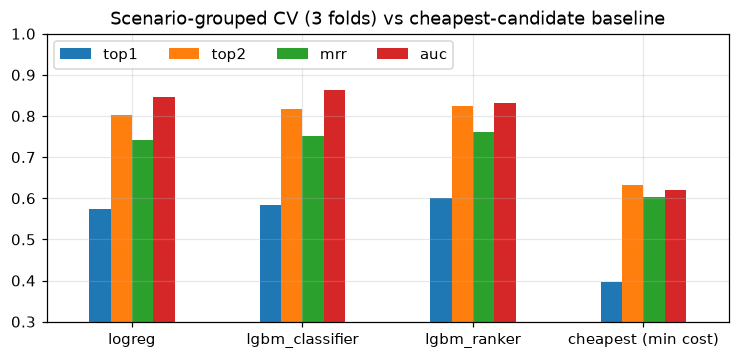

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.4))
comparison[["top1", "top2", "mrr", "auc"]].plot.bar(ax=ax, rot=0)
ax.set(title="Scenario-grouped CV (3 folds) vs cheapest-candidate baseline", ylim=(0.3, 1.0))
ax.legend(ncol=4, loc="upper left")
plt.show()

**Result.**
* All three models beat the best baseline by a wide margin (top-1 0.57-0.60 vs 0.40-0.43), so the signal is real.
* Logistic regression already gets most of the way: the signal is largely monotone in a few features.
* **LambdaRank has the best top-1/top-2/MRR but the *lowest* AUC.** That is the metric argument from section 4
  made concrete: the pointwise classifier is better at separating chosen vs not-chosen *across the whole dataset*
  (AUC), LambdaRank is better at ordering candidates *within a decision* - which is the only thing the dispatcher
  uses. Selecting by AUC would have picked the wrong model.

**Decision:** LambdaRank, selected on top-1 (this is what `train.py` automates).

## 7 · Hyper-parameter sweep (LambdaRank)

A small, targeted grid rather than a large random search: the dataset is ~60 k rows, so the main risk is
over-fitting with too many leaves or trees. `min_child_samples` controls leaf size (regularisation).

In [11]:
grid = [
    {"num_leaves": 15, "n_estimators": 200, "min_child_samples": 20},
    {"num_leaves": 31, "n_estimators": 300, "min_child_samples": 20},   # production default
    {"num_leaves": 63, "n_estimators": 300, "min_child_samples": 20},
    {"num_leaves": 31, "n_estimators": 600, "min_child_samples": 20},
    {"num_leaves": 31, "n_estimators": 300, "min_child_samples": 100},
    {"num_leaves": 127, "n_estimators": 300, "min_child_samples": 50},
]
t0 = time.perf_counter()
sweep = pd.DataFrame([{**g, **cv_score("lgbm_ranker", train_df, train_df.scenario_id.values, **g)} for g in grid])
print(f"sweep done in {time.perf_counter() - t0:.0f}s")
display(sweep.sort_values("top1", ascending=False).style.format(precision=3).highlight_max(subset=["top1"], color="#d4f4dd"))

sweep done in 214s


,num_leaves,n_estimators,min_child_samples,top1,top2,mrr,auc
0,15,200,20,0.600,0.824,0.760,0.828
1,31,300,20,0.600,0.825,0.760,0.832
4,31,300,100,0.597,0.825,0.759,0.832
2,63,300,20,0.589,0.813,0.752,0.834
3,31,600,20,0.585,0.816,0.751,0.831
5,127,300,50,0.582,0.810,0.748,0.837


**Result.** The response surface is flat around the defaults (0.600 for 15 or 31 leaves) and *degrades* with more
capacity (63-127 leaves or 600 trees: 0.582-0.589) - classic over-fitting to the teacher's noise.

**Decision:** keep the production defaults (31 leaves, 300 trees). The 15-leaf / 200-tree model is equally accurate
and ~2x cheaper at inference, a good option if per-request latency became the constraint. Gains from tuning are
small compared to gains from features (section 8) - effort is better spent there.

## 8 · Learning curve and feature ablation

**Learning curve** - train on the first *k* training scenarios, evaluate on the fixed held-out test set.
Answers: *would more synthetic days help?* (cheap to generate) vs *are we limited by features / the teacher?*

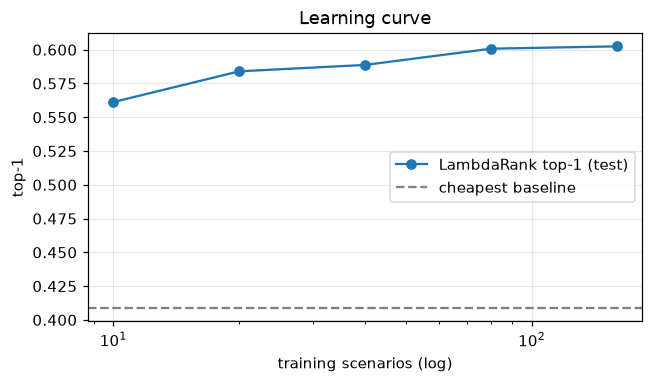

,train_scenarios,rows,top1,top2,mrr,auc
0,10,3064,0.561,0.792,0.733,0.821
1,20,7527,0.584,0.809,0.748,0.827
2,40,15578,0.589,0.808,0.751,0.829
3,80,31250,0.601,0.834,0.762,0.834
4,160,62119,0.602,0.837,0.764,0.839


In [12]:
train_sids = sorted(set(train_df.scenario_id))
lc = []
for k in [10, 20, 40, 80, len(train_sids)]:
    sub = train_df[train_df.scenario_id.isin(train_sids[:k])]
    scorer = fit("lgbm_ranker", *xyd(sub))
    lc.append({"train_scenarios": k, "rows": len(sub), **decision_metrics(test_df, scorer.score(test_df[FEATURE_NAMES].values))})
lc = pd.DataFrame(lc)

cheapest_test = decision_metrics(test_df, -test_df.cost.values)["top1"]
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(lc.train_scenarios, lc.top1, "o-", label="LambdaRank top-1 (test)")
ax.axhline(cheapest_test, color="grey", ls="--", label="cheapest baseline")
ax.set(xscale="log", xlabel="training scenarios (log)", ylabel="top-1", title="Learning curve")
ax.legend()
plt.show()
display(lc)

**Result.** Top-1 rises from 0.56 (10 days) to 0.60 (80 days) and is **flat from 80 to 160** days.
More synthetic data will not help; the ceiling comes from (a) what the features can observe online and (b) how
deterministic the teacher is given those features. Next improvements must come from better features, a better
teacher, or on-policy data (DAgger), not volume.

**Feature-group ablation** - drop one group at a time, retrain, measure the test top-1 drop. Unlike gain importance,
this measures what the model *cannot recover* from the other features (correlated features compensate for each other).

,test top-1,delta vs all
(all features),0.602,0.000
"- geometry/time (travel, idle, slack, hour)",0.560,-0.043
"- cost-derived (cost, rank, gap)",0.607,0.005
- skill & scarcity,0.573,-0.029
- load & capacity,0.601,-0.002
- job context,0.600,-0.002
only cost-derived,0.402,-0.201


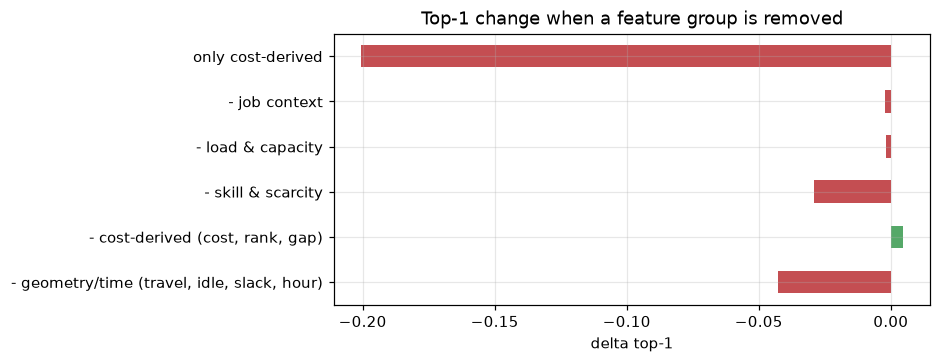

In [13]:
groups = {
    "geometry/time (travel, idle, slack, hour)": ["travel_km", "idle_min", "slack_min", "start_hour"],
    "cost-derived (cost, rank, gap)": ["cost", "cost_rank", "cost_gap_to_best"],
    "skill & scarcity": ["overskill", "job_skill_supply", "tech_n_skills", "tech_rarity", "tech_skill_level"],
    "load & capacity": ["tech_jobs_done", "tech_capacity_left", "tech_shift_left_min"],
    "job context": ["n_feasible", "priority", "job_duration", "window_len"],
}


def test_top1(features: list[str]) -> float:
    scorer = fit("lgbm_ranker", *xyd(train_df, features))
    return decision_metrics(test_df, scorer.score(test_df[features].values))["top1"]


full = test_top1(FEATURE_NAMES)
abl = {"(all features)": full}
for name, cols in groups.items():
    abl[f"- {name}"] = test_top1([f for f in FEATURE_NAMES if f not in cols])
abl["only cost-derived"] = test_top1(groups["cost-derived (cost, rank, gap)"])
abl = pd.Series(abl, name="test top-1").to_frame()
abl["delta vs all"] = abl["test top-1"] - full
display(abl)

fig, ax = plt.subplots(figsize=(7, 3.2))
abl["delta vs all"].iloc[1:].plot.barh(ax=ax, color=["#c44e52" if v < 0 else "#55a868" for v in abl["delta vs all"].iloc[1:]])
ax.set(title="Top-1 change when a feature group is removed", xlabel="delta top-1")
plt.show()

**Result.**
* **Geometry/time is the most important group** (-4.3 pts without it): travel, idle, slack and time of day.
* **Skill & scarcity is second** (-2.9 pts): this is the "keep rare technicians free" knowledge a greedy rule lacks.
* **Cost-derived features are redundant** (removing them changes nothing, +0.5 pts within noise): the model can
  recombine the raw components better than our hand-weighted sum. Alone they score 0.40 - exactly the cheapest
  baseline, as expected.
* Load/capacity and job context add little *on top of* the rest (they are strongly correlated with other features,
  e.g. `tech_jobs_done` and `tech_capacity_left` are perfectly anti-correlated since `max_jobs` is constant).

**Decision:** keep all features in production (no accuracy cost, and `cost`/`cost_rank` make SHAP explanations
easier to read for dispatchers). For a leaner model, drop the cost-derived group and one of each redundant pair.

## 9 · Final model on the held-out test set

Selected configuration (from sections 6-7): **LambdaRank, production defaults**. Retrain on all training scenarios,
evaluate once on the untouched test scenarios.

In [14]:
final = fit("lgbm_ranker", *xyd(train_df))
test_scores = final.score(test_df[FEATURE_NAMES].values)
final_metrics = pd.DataFrame({
    "LambdaRank (final)": decision_metrics(test_df, test_scores),
    "cheapest baseline": decision_metrics(test_df, -test_df.cost.values),
    "random (expected)": random_expected,
}).T
display(final_metrics)

,top1,top2,mrr,auc
LambdaRank (final),0.602,0.837,0.764,0.839
cheapest baseline,0.409,0.655,0.615,0.620
random (expected),0.233,0.467,0.470,0.500


### 9.1 Error analysis - where does the model miss?

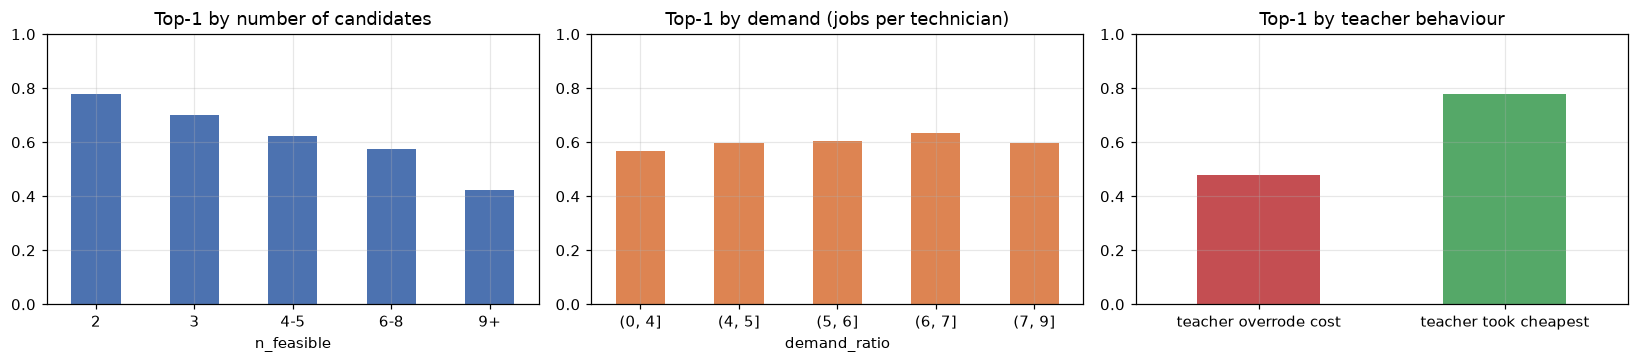

Share of test decisions where the teacher overrode the cheapest option: 59.1%


,top1,decisions
n_feasible,,
2,0.777,391
3,0.701,334
4-5,0.622,542
6-8,0.575,520
9+,0.422,540


,top1
demand_ratio,
"(0, 4]",0.568
"(4, 5]",0.598
"(5, 6]",0.604
"(6, 7]",0.633
"(7, 9]",0.596


,top1
teacher overrode cost,0.480
teacher took cheapest,0.779


In [15]:
ev = test_df[["decision_id", "label", "n_feasible", "demand_ratio", "start_hour", "cost_rank"]].copy()
ev["score"] = test_scores
ev = ev[ev.n_feasible >= 2]
ev["rank"] = ev.groupby("decision_id")["score"].rank(ascending=False, method="first")
pos = ev[ev.label == 1].copy()
pos["hit"] = pos["rank"] == 1
pos["teacher_took_cheapest"] = pos.cost_rank == 0

fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
by_n = pos.groupby(pd.cut(pos.n_feasible, [1, 2, 3, 5, 8, 100], labels=["2", "3", "4-5", "6-8", "9+"]), observed=True).hit.mean()
by_n.plot.bar(ax=axes[0], rot=0, color="#4c72b0")
axes[0].set(title="Top-1 by number of candidates", ylim=(0, 1))
by_r = pos.groupby(pd.cut(pos.demand_ratio, [0, 4, 5, 6, 7, 9]), observed=True).hit.mean()
by_r.plot.bar(ax=axes[1], rot=0, color="#dd8452")
axes[1].set(title="Top-1 by demand (jobs per technician)", ylim=(0, 1))
by_c = pos.groupby("teacher_took_cheapest").hit.mean()
by_c.index = ["teacher overrode cost", "teacher took cheapest"]
by_c.plot.bar(ax=axes[2], rot=0, color=["#c44e52", "#55a868"])
axes[2].set(title="Top-1 by teacher behaviour", ylim=(0, 1))
plt.tight_layout()
plt.show()
print(f"Share of test decisions where the teacher overrode the cheapest option: {(~pos.teacher_took_cheapest).mean():.1%}")
display(pd.DataFrame({"top1": by_n, "decisions": pos.groupby(pd.cut(pos.n_feasible, [1, 2, 3, 5, 8, 100], labels=["2", "3", "4-5", "6-8", "9+"]), observed=True).size()}))
display(pd.DataFrame({"top1": by_r}))
display(by_c.to_frame("top1"))

**Result.**
* **Top-1 falls with candidate count** (0.78 with 2 candidates -> 0.42 with 9+) - expected, the task gets harder.
  Relative to random it is the opposite: 1.6x random at 2 candidates, **~4-5x random at 9+**. The model adds the most
  value exactly where a human dispatcher has the most options to weigh.
* **Demand level barely matters** (0.57-0.63 across 4-9 jobs/technician): the model generalises across load levels
  it was trained on.
* **The real failure mode:** when the teacher took the cheapest option, the model agrees 78 % of the time; when the
  teacher *overrode* cost (59 % of decisions), only 48 %. Those overrides depend on future jobs and other
  technicians' plans - information an online policy fundamentally cannot observe. This is the irreducible part of
  the batch-vs-online gap, not a modelling bug.

### 9.2 Is the model's confidence meaningful? (calibration)

The UI shows a "confidence" = softmax of LambdaRank scores within a decision. Ranking scores are **not
probabilities**, so we check empirically: when the model says 70 %, is it right ~70 % of the time?

,mean_conf,accuracy,n
bin,,,
"(0.0, 0.3]",0.256,0.253,166
"(0.3, 0.45]",0.380,0.413,579
"(0.45, 0.6]",0.521,0.535,593
"(0.6, 0.75]",0.674,0.730,497
"(0.75, 0.9]",0.818,0.863,342
"(0.9, 1.0]",0.939,0.973,150


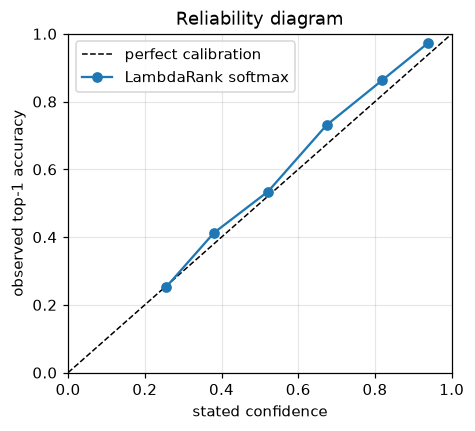

In [16]:
ev["conf"] = ev.groupby("decision_id")["score"].transform(lambda s: np.exp(s - s.max()) / np.exp(s - s.max()).sum())
top = ev[ev["rank"] == 1].copy()
top["bin"] = pd.cut(top.conf, [0, 0.3, 0.45, 0.6, 0.75, 0.9, 1.0])
cal = top.groupby("bin", observed=True).agg(mean_conf=("conf", "mean"), accuracy=("label", "mean"), n=("label", "size"))
display(cal)

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
ax.plot(cal.mean_conf, cal.accuracy, "o-", label="LambdaRank softmax")
ax.set(xlabel="stated confidence", ylabel="observed top-1 accuracy", title="Reliability diagram", xlim=(0, 1), ylim=(0, 1))
ax.legend()
plt.show()

**Result.** The softmax confidence is close to the diagonal and slightly **under-confident** at the high end
(stated 0.82 -> observed 0.86; stated 0.94 -> observed 0.97). Good enough to use as a *routing signal*:
e.g. auto-dispatch when confidence > 0.75 (~86-97 % agreement with the optimiser) and ask a human dispatcher to
confirm below 0.45. If exact probabilities were needed, a temperature parameter fitted on validation data would
calibrate it with one scalar.

## 10 · Explainability with SHAP

LightGBM computes exact **TreeSHAP** values natively (`predict(..., pred_contrib=True)`), so no extra dependency is
needed. For each candidate, contributions sum (with a bias term) to its raw score; positive values push the
candidate up the ranking. This is what the UI shows per assignment.

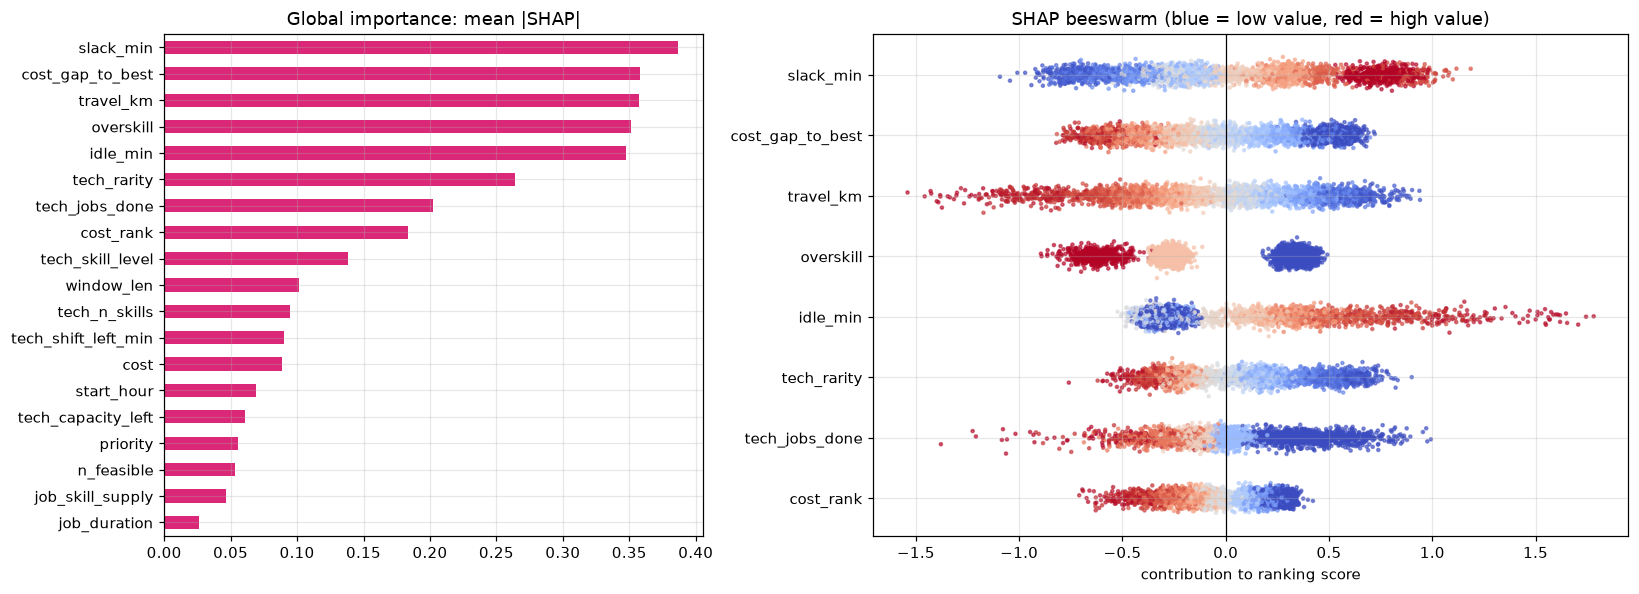

In [17]:
X_te = test_df[FEATURE_NAMES].values
shap_vals = final.contributions(X_te)
mean_abs = pd.Series(np.abs(shap_vals).mean(0), index=FEATURE_NAMES).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.4]})
mean_abs.plot.barh(ax=axes[0], color="#db2777")
axes[0].set(title="Global importance: mean |SHAP|")

top_feats = mean_abs.index[::-1][:8]
rng_plot = np.random.default_rng(0)
sample = rng_plot.choice(len(X_te), size=min(4000, len(X_te)), replace=False)
for i, f in enumerate(top_feats[::-1]):
    j = FEATURE_NAMES.index(f)
    vals = X_te[sample, j]
    colour = pd.Series(vals).rank(pct=True).values  # colour = feature value percentile
    axes[1].scatter(shap_vals[sample, j], i + rng_plot.normal(0, 0.08, len(sample)), c=colour, cmap="coolwarm", s=4, alpha=0.6)
axes[1].set_yticks(range(len(top_feats)), top_feats[::-1])
axes[1].axvline(0, color="k", lw=0.8)
axes[1].set(title="SHAP beeswarm (blue = low value, red = high value)", xlabel="contribution to ranking score")
plt.tight_layout()
plt.show()

**How to read it.** Each dot is one candidate; x = how much that feature moved its score; colour = the feature's value.
Measured on the test set (Spearman correlation between feature value and its SHAP value):

| Feature | Direction | Meaning |
|---|---|---|
| `slack_min` | +0.95 | arriving with time to spare is strongly preferred (robust plans) |
| `cost_gap_to_best`, `cost_rank` | -0.97 | being much worse than the cheapest option hurts... but it is one signal among many |
| `travel_km` | -0.98 | distance pushes candidates down |
| `overskill` | -0.91 | don't spend senior technicians on simple jobs |
| `idle_min` | **+0.74** | *more* idle is rewarded - inherited from the round-based teacher (section 4) |
| `tech_rarity` | -0.95 | keep rare-skill technicians available |
| `tech_jobs_done` | -0.92 | spread work across the fleet |

The `idle_min` row is a good example of SHAP **auditing the teacher**, not just the model: the student faithfully
copied a questionable habit of the optimiser. In production this would trigger a fix in the teacher (time-aware
rounds or a VRP solver), not in the model.

### 10.1 One decision, explained
A test decision where the teacher did **not** pick the cheapest technician and the model got it right - the
interesting case to walk through in an interview.

,label,score,cost,cost_rank,travel_km,idle_min,slack_min,overskill,tech_rarity,tech_jobs_done
56,1,1.41,9.53,2.00,5.96,135.68,180.00,1.00,0.94,0.00
54,0,-0.78,1.31,0.00,11.81,0.00,136.66,0.00,1.88,1.00
55,0,-1.64,3.99,1.00,9.49,0.00,10.70,1.00,0.94,3.00


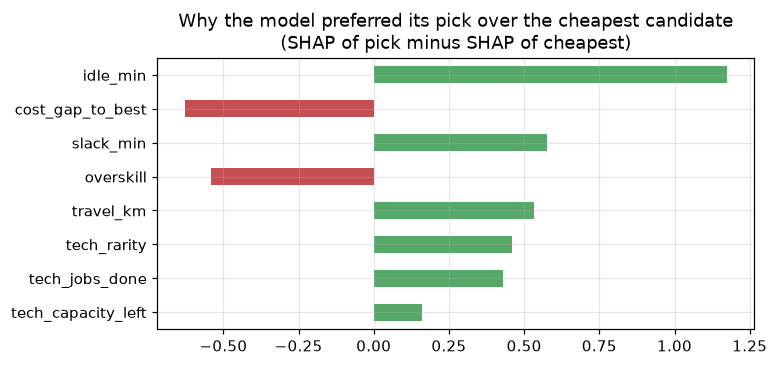

In [18]:
ev_full = test_df.copy()
ev_full["score"] = test_scores
cand_dec = pos[(pos.hit) & (~pos.teacher_took_cheapest) & pos.n_feasible.between(3, 6)].decision_id
example_id = int(cand_dec.iloc[0])
ex = ev_full[ev_full.decision_id == example_id]
cols = ["label", "score", "cost", "cost_rank", "travel_km", "idle_min", "slack_min", "overskill", "tech_rarity", "tech_jobs_done"]
display(ex[cols].sort_values("score", ascending=False).style.format(precision=2).highlight_max(subset=["label"], color="#d4f4dd"))

idx = ex.index.values
pick = idx[np.argmax(ex.score.values)]
cheapest = idx[np.argmin(ex.cost.values)]
diff = pd.Series(shap_vals[pick] - shap_vals[cheapest], index=FEATURE_NAMES)
diff = diff[diff.abs().sort_values(ascending=False).index][:8]
fig, ax = plt.subplots(figsize=(7, 3.2))
diff[::-1].plot.barh(ax=ax, color=["#55a868" if v > 0 else "#c44e52" for v in diff[::-1]])
ax.set(title="Why the model preferred its pick over the cheapest candidate\n(SHAP of pick minus SHAP of cheapest)")
plt.show()

Reading the chart: green bars are reasons the pick outranks the cheapest candidate, red bars are reasons against
that were outweighed. This is the same mechanism the API uses for `top_factors` in each ML explanation.

## 11 · Does better imitation mean better dispatch?

Top-1 is a proxy. What the business cares about is fulfilment, priority service, travel and fairness. We run both
dispatchers end-to-end on the **held-out test scenarios**:

* **Hungarian** - batch teacher (needs the whole day in advance),
* **ML** - online, LambdaRank-ranked, one request at a time.

In [19]:
test_scen = [scenarios[i] for i in sorted(test_sids)]
t0 = time.perf_counter()
biz = business_eval(test_scen, WEIGHTS, final)
print(f"evaluated {len(test_scen)} scenarios in {time.perf_counter() - t0:.0f}s")
agree = biz.pop("ml_agreement_with_hungarian")
biz_df = pd.DataFrame(biz).T
display(biz_df.style.format("{:.2f}"))
print(f"ML vs Hungarian - same technician for the same job: {agree:.1%}")

evaluated 40 scenarios in 50s


,fulfillment_rate,priority_weighted_fulfillment,high_priority_fulfillment,avg_travel_km,avg_idle_min,utilization,workload_std,runtime_ms
hungarian,73.06,78.32,88.04,6.39,38.97,62.72,0.84,103.85
ml,76.04,75.40,74.78,7.33,29.72,67.18,1.09,1142.72


ML vs Hungarian - same technician for the same job: 38.4%


**Result (40 unseen days).**

| | Hungarian (batch) | ML (online) |
|---|---|---|
| Fulfilment | 73.1 % | **76.0 %** |
| Priority-weighted | **78.3 %** | 75.4 % |
| High-priority (4-5) | **88.0 %** | 74.8 % |
| Avg idle min | 39.0 | **29.7** |
| Utilisation | 62.7 % | **67.2 %** |
| Workload std | **0.84** | 1.09 |

* **The online policy serves *more* jobs but *less important* ones.** Hungarian sees all requests at once and lets
  urgent jobs win the competition for technicians; an online dispatcher assigns in arrival order and cannot hold a
  technician back for an urgent job that hasn't arrived yet.
* **ML keeps technicians busier** (less idle, higher utilisation) because it doesn't inherit the round-based
  "wait for a better job" plans in full - it only imitates them locally.
* Only 38 % of (job, technician) pairs match Hungarian, yet outcomes are close: many different assignments are
  near-equivalent. **Imitation accuracy is a proxy; outcome metrics are the real test.**

### 11.1 Per scenario type (presets, 3 seeds each)

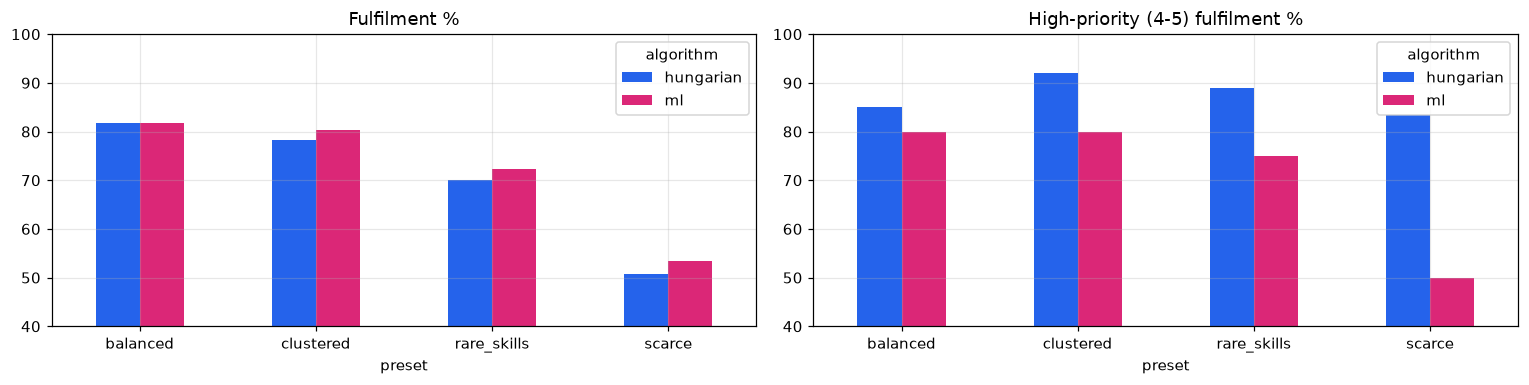

fulfillment_rate       priority_weighted_fulfillment       high_priority_fulfillment       avg_travel_km     
algorithm          hungarian    ml                     hungarian    ml                 hungarian    ml     hungarian   ml
preset                                                                                                                   
balanced                81.7  81.7                          84.8  81.3                      85.0  79.9           8.2  7.9
clustered               78.3  80.4                          83.9  80.5                      91.9  79.9           5.0  5.6
rare_skills             70.0  72.4                          75.5  72.7                      89.0  75.0           8.0  9.2
scarce                  50.7  53.3                          61.7  52.4                      83.4  49.9           6.8  9.8

In [20]:
rows = []
for preset in [p for p in PRESETS if p != "large"]:
    for seed in (1, 2, 3):
        sc = generate_preset(preset, seed)
        for r in (allocate_hungarian(sc, WEIGHTS), allocate_online(sc, WEIGHTS, final)):
            rows.append({"preset": preset, "algorithm": r.algorithm, **{k: r.metrics[k] for k in
                         ["fulfillment_rate", "priority_weighted_fulfillment", "high_priority_fulfillment", "avg_travel_km"]}})
per_preset = pd.DataFrame(rows).groupby(["preset", "algorithm"]).mean().unstack("algorithm")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
per_preset["fulfillment_rate"].plot.bar(ax=axes[0], rot=0, color=["#2563eb", "#db2777"])
axes[0].set(title="Fulfilment %", ylim=(40, 100))
per_preset["high_priority_fulfillment"].plot.bar(ax=axes[1], rot=0, color=["#2563eb", "#db2777"])
axes[1].set(title="High-priority (4-5) fulfilment %", ylim=(40, 100))
plt.tight_layout()
plt.show()
display(per_preset.round(1))

## 12 · Scale: compounding error and latency

Two questions for production:
1. **Does the policy drift from the teacher on bigger days?** Agreement = share of Hungarian's (job, technician)
   pairs the ML dispatcher reproduces. Early divergence changes the fleet state, so later decisions happen in states
   the model never saw with teacher forcing.
2. **What does it cost per request?** Hungarian re-solves a matrix for the whole batch; the ML dispatcher scores
   only the current request's candidates.

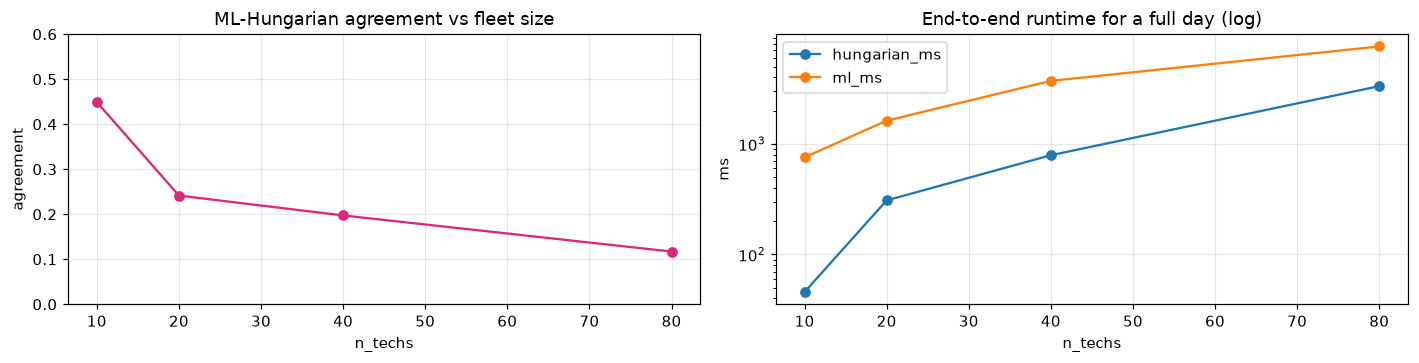

,n_jobs,agreement,hungarian_ms,ml_ms,ml_ms_per_request,fulfil_gap
n_techs,,,,,,
10,75.0,0.45,45.75,755.81,10.08,4.00
20,150.0,0.24,308.53,1622.21,10.81,3.67
40,300.0,0.20,790.03,3716.14,12.39,4.67
80,600.0,0.12,3330.90,7612.50,12.69,2.83


In [21]:
scale = []
for n_techs in [10, 20, 40, 80]:
    for seed in (1, 2):
        sc = generate_scenario(seed=seed, n_techs=n_techs, n_jobs=int(n_techs * 7.5), clusters=2)
        h = allocate_hungarian(sc, WEIGHTS)
        m = allocate_online(sc, WEIGHTS, final)
        scale.append({"n_techs": n_techs, "n_jobs": len(sc.jobs), "agreement": agreement(h, m),
                      "hungarian_ms": h.runtime_ms, "ml_ms": m.runtime_ms, "ml_ms_per_request": m.runtime_ms / len(sc.jobs),
                      "fulfil_gap": m.metrics["fulfillment_rate"] - h.metrics["fulfillment_rate"]})
scale = pd.DataFrame(scale).groupby("n_techs").mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
scale.agreement.plot(ax=axes[0], marker="o", color="#db2777")
axes[0].set(title="ML-Hungarian agreement vs fleet size", ylabel="agreement", ylim=(0, 0.6))
scale[["hungarian_ms", "ml_ms"]].plot(ax=axes[1], marker="o", logy=True)
axes[1].set(title="End-to-end runtime for a full day (log)", ylabel="ms")
plt.tight_layout()
plt.show()
display(scale.round(2))

**Result.**
* **Compounding error is visible:** agreement falls from 0.45 (10 technicians) to 0.12 (80). Per-decision accuracy
  on teacher states is ~0.60 regardless of size, so the decay comes from drift: one different choice changes the
  fleet state for every later decision. Yet the fulfilment gap stays positive (+3 to +5 pts) - the policy drifts to
  *different*, not *worse*, plans. The fix is **DAgger**: run the model, ask the teacher what it would do in the
  states the model actually visits, add those labels, retrain.
* **Latency:** ML costs ~1.4-2.3 ms per request and grows linearly with the day. Hungarian's total grows
  super-linearly (x8 fleet -> x140 runtime: 5 ms -> 717 ms) because every round re-solves an
  O(n^2 m) assignment over more jobs and more rounds. At this size Hungarian is still cheap, so the ML argument is
  **decision-without-batching**, not raw speed; extrapolating the curves, the crossover is around ~100+ technicians.

## 13 · Conclusions and decisions carried into production

| Question | Evidence | Decision in `train.py` |
|---|---|---|
| Is there signal beyond cost? | Teacher takes cheapest in only ~40 % of decisions; models reach 0.60 top-1 vs 0.43 best baseline | Use a learned scorer |
| Classification or ranking? | LambdaRank best top-1/MRR, lowest AUC | `lgbm_ranker`, selection metric = top-1 |
| Split protocol | No leakage gap on synthetic data, but scenario split is the one valid on real data | `GroupKFold` + held-out scenarios |
| Hyper-parameters | Flat near defaults; larger models over-fit | 31 leaves, 300 trees |
| More data? | Learning curve flat after ~80 days | 200 scenarios is enough |
| Features | Geometry/time and skill scarcity matter; cost-derived redundant | Keep all (readability of explanations) |
| Trust signal | Softmax confidence roughly calibrated | Shown in UI as `confidence` |
| Business value | +3 pts fulfilment and higher utilisation vs Hungarian; trades high-priority service for volume | Online dispatch with hard constraints first |

**Limitations.** Synthetic world (the model learns the generator); the teacher is round-based Hungarian, not a true
VRP optimum, so the student inherits its quirks (e.g. tolerance for idle time); teacher forcing -> compounding error.

**Next steps, in order of expected value.**
1. **DAgger** - collect teacher labels on states the model visits; directly targets the agreement decay.
2. **Priority-aware online policy** - allow a short "hold" for high-priority demand forecasts, or a rolling 15-min
   Hungarian micro-batch; targets the high-priority gap.
3. **Better teacher** - a VRP solver with time windows (e.g. OR-Tools) as the label source.
4. **Real data** - replace synthetic days with dispatch history; switch to a time-based split; monitor drift on
   feature distributions and on the top-1 agreement with a nightly batch re-optimisation.